# Project 2: Scene Reconstruction

This project addresses scene reconstruction.
You will use data from the public dataset [2014 Stereo Dataset](https://vision.middlebury.edu/stereo/data/scenes2014/), which contains stereo images of different objects.
You will estimate disparity and depth maps from the images, apply graphical models to smooth the results, and perform surface extraction of the 3D scene.

**Group Rules:**
Solo submissions will not be graded, please form groups of ideally three members with at least two. Each group member will need to mark their contributions to the code and this person will be responsible to answer questions. Make sure to register on time for the group presentations, registration will be possible until the submission deadline.

Submit your group's results through ILIAS and make sure all group members are registered. Please only upload your code and notebooks, **do not** upload the image data with your submission.


In [ ]:
import cv2
from PIL import Image
from tqdm.auto import tqdm
try:
    import gco
except Exception:
    pass
import numpy as np
import importlib
import matplotlib.pyplot as plt
#importlib.reload(functions_student)
from functions_student import *
%matplotlib inline


## Exercise 1

**Learning goals:** F-matrix estimation & Rectification

The goal of this exercise is to implement the F-matrix estimation to rectify two stereo images.

1. Load the provided stereo images (`data/img0.jpg` and `data/img1.jpg`). *Note: You are welcome to use your own camera photos to test your implementation, but your final code must work on the provided data.*
2. Use what you learned about feature descriptors and key point matching to find correspondences between the two images. Plot the detected points and matches.
3. Use identified matches to estimate the fundamental matrix (F-matrix). You may use existing implementations for key point detection and matching, but you should implement the matrix estimation yourself.
4. Apply the estimated F-matrix to rectify the images.


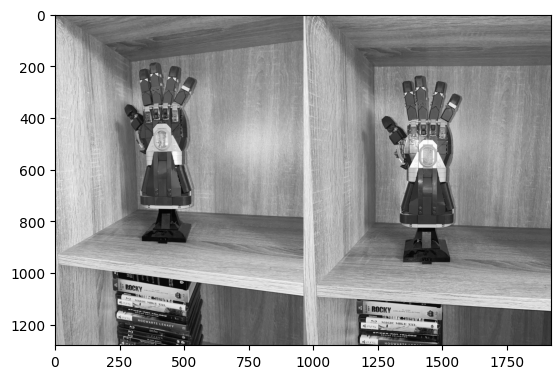

In [ ]:
# Load images for Exercise 1
img1_ex1 = np.array(Image.open('/content/img0.jpg').convert('L'))
img2_ex1 = np.array(Image.open('/content/img1.jpg').convert('L'))
plt.imshow(np.hstack((img1_ex1, img2_ex1)), cmap='gray')
plt.show()


Good matches before RANSAC: 379
Matches after RANSAC: 220


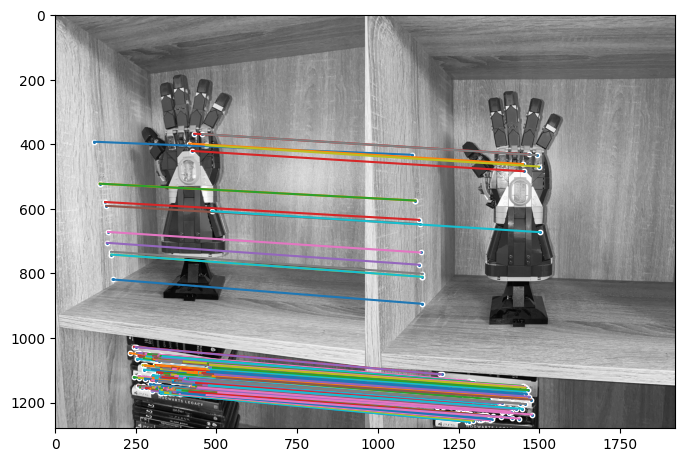

In [ ]:
# Find correspondences between img1_ex1 and img2_ex1
# 1. Extract keypoints and descriptors
keypoints1, descriptors1 = get_keypoints(img1_ex1)
keypoints2, descriptors2 = get_keypoints(img2_ex1)

# 2. Match descriptors
match_indices = matching(
    descriptors1,
    descriptors2,
    max_ratio=0.75,
    cross_checking=True
)

pts1 = keypoints1[match_indices[:, 0]]
pts2 = keypoints2[match_indices[:, 1]]

print("Good matches before RANSAC:", len(pts1))

# 3. Filter matches using RANSAC (homography is used only to remove bad matches)
H_match, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, 5.0)
mask = mask.ravel().astype(bool)

# IMPORTANT: Store your final matched keypoints in `keypoints1_match` and `keypoints2_match`
keypoints1_match = pts1[mask].astype(np.float32)
keypoints2_match = pts2[mask].astype(np.float32)

print("Matches after RANSAC:", len(keypoints1_match))

# 4. Plot the matching result
show_matching_result(
    img1_ex1,
    img2_ex1,
    keypoints1_match,
    keypoints2_match
)
plt.show()

In [ ]:
# Estimate the F-matrix manually using SVD and normalization
def normalize_points(points):
    """
    Normalize 2D points so that:
    1. centroid is at origin
    2. average distance from origin is sqrt(2)
    """

    mean = np.mean(points, axis=0)
    shifted_points = points - mean

    distances = np.sqrt(np.sum(shifted_points ** 2, axis=1))
    mean_distance = np.mean(distances)

    scale = np.sqrt(2) / mean_distance

    T = np.array([
        [scale, 0, -scale * mean[0]],
        [0, scale, -scale * mean[1]],
        [0, 0, 1]
    ])

    points_h = np.hstack((points, np.ones((points.shape[0], 1))))
    normalized_points_h = (T @ points_h.T).T

    return normalized_points_h, T


def estimate_fundamental_matrix(points1, points2):
    """
    Estimate F using normalized 8-point algorithm.
    points1: matched points from image 1, shape Nx2
    points2: matched points from image 2, shape Nx2
    """

    points1_norm, T1 = normalize_points(points1)
    points2_norm, T2 = normalize_points(points2)

    A = []

    for p1, p2 in zip(points1_norm, points2_norm):
        x1, y1, _ = p1
        x2, y2, _ = p2

        A.append([
            x2 * x1,
            x2 * y1,
            x2,
            y2 * x1,
            y2 * y1,
            y2,
            x1,
            y1,
            1
        ])

    A = np.array(A)

    # Solve Af = 0 using SVD
    U, S, Vt = np.linalg.svd(A)

    F_normalized = Vt[-1].reshape(3, 3)

    # Enforce rank-2 constraint
    U, S, Vt = np.linalg.svd(F_normalized)
    S[-1] = 0
    F_normalized_rank2 = U @ np.diag(S) @ Vt

    # Denormalize F
    F = T2.T @ F_normalized_rank2 @ T1

    # Scale F for readable output
    F = F / F[-1, -1]

    return F
# IMPORTANT: Store the result in a variable named `F`
F = estimate_fundamental_matrix(keypoints1_match, keypoints2_match)
print('Fundamental Matrix:\n', F)


Fundamental Matrix:
 [[-2.60240066e-06  1.55593901e-05 -2.19842173e-02]
 [-9.38479289e-06  8.23170587e-07  3.63062109e-02]
 [ 2.16218550e-02 -4.23849004e-02  1.00000000e+00]]


Rectification success: True
H1:
 [[ 4.22750107e-02  1.15712843e-02 -2.24097834e+00]
 [-2.51040654e-02  4.03949278e-02  1.72702355e+01]
 [-9.90938438e-06 -7.05724063e-06  5.49069870e-02]]
H2:
 [[ 7.30985351e-01  3.15134818e-01 -7.25592522e+01]
 [-6.45639071e-01  8.10628713e-01  4.31104378e+02]
 [-3.90236775e-04 -1.68234828e-04  1.29498394e+00]]


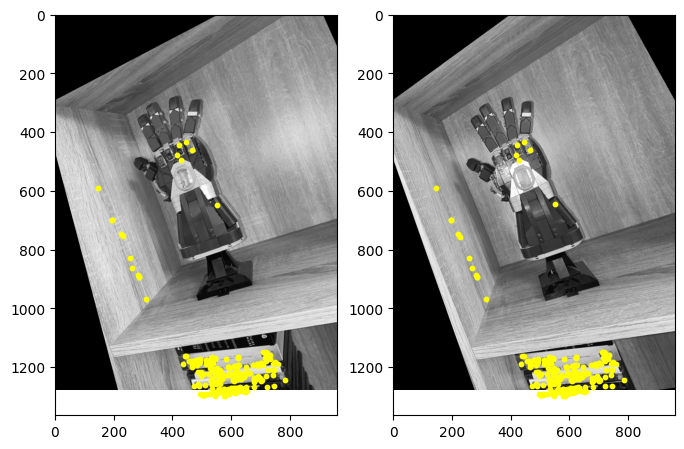

In [ ]:
# Rectify the images using the estimated F-matrix
h, w = img1_ex1.shape
# 1. Compute rectification homographies using cv2.stereoRectifyUncalibratedsuccess, H1, H2 = cv2.stereoRectifyUncalibrated(
success, H1, H2 = cv2.stereoRectifyUncalibrated(
    np.float32(keypoints1_match),
    np.float32(keypoints2_match),
    F,
    imgSize=(w, h)
)
print("Rectification success:", success)
#    (Store them in variables H1 and H2)
# 2. Apply homographies
img1_rectified_ex1 = cv2.warpPerspective(img1_ex1, H1, (w, h))
img2_rectified_ex1 = cv2.warpPerspective(img2_ex1, H2, (w, h))

print("H1:\n", H1)
print("H2:\n", H2)

# 2. Apply the homographies using cv2.warpPerspective
#    (Store the warped images in img1_rectified_ex1 and img2_rectified_ex1)
#H1 = None
#H2 = None
#img1_rectified_ex1 = None
#img2_rectified_ex1 = None

# --- Visualization ---
def transform_points(points, matrix):
    points = np.hstack((points, np.ones((len(points), 1), dtype=np.float32)))
    points = (matrix @ points.T).T
    points = points[:, :2] / points[:, 2, np.newaxis]
    return points

if keypoints1_match is not None and H1 is not None:
    keypoints1_rectified_ex1 = transform_points(keypoints1_match, H1)
    keypoints2_rectified_ex1 = transform_points(keypoints2_match, H2)
    fig, axes = plt.subplots(1,2, figsize=(8,8))
    axes[0].imshow(img1_rectified_ex1, cmap='gray')
    axes[0].scatter(keypoints1_rectified_ex1[:,0], keypoints1_rectified_ex1[:,1], s=10, c='yellow')
    axes[1].imshow(img2_rectified_ex1, cmap='gray')
    axes[1].scatter(keypoints2_rectified_ex1[:,0], keypoints2_rectified_ex1[:,1], s=10, c='yellow')
    plt.show()


## Exercise 2

**Learning goals:** Compute scene depth using block matching

After rectifying images in the last exercise, the goal of this exercise will be to compute the scene depth. We will use a different pair of images for this task, located in `Sword1-perfect/`.

1. Compute the disparity using the methods described in the lecture.
   *Hint: We recommend using Sum of Absolute Differences (SAD) with a window size of 7x7 and the dynamically estimated maximum disparity.*
2. Implement Left-Right cross-checking to resolve ambiguous matches.
3. Use the computed disparity to estimate and display the depth.

**Tip:** If your implementation is too slow, you may downscale images to speed up computation.
**Note:** Please implement these algorithms yourself in `functions.py` or use the provided skeleton.


In [ ]:
# Load images for Exercise 2 (Sword1-perfect)
img1_orig = np.array(Image.open('/content/im0.png').convert('RGB'))
img2_orig = np.array(Image.open('/content/im1.png').convert('RGB'))


In [ ]:
# Estimate maximum disparity using keypoints
# 1. Extract keypoints and match them between img1_orig and img2_orig
img1_gray = cv2.cvtColor(img1_orig, cv2.COLOR_RGB2GRAY)
img2_gray = cv2.cvtColor(img2_orig, cv2.COLOR_RGB2GRAY)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1_gray, None)
kp2, des2 = sift.detectAndCompute(img2_gray, None)

# 2. Match descriptors
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

pts1 = []
pts2 = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        pts1.append(kp1[m.queryIdx].pt)
        pts2.append(kp2[m.trainIdx].pt)

pts1 = np.array(pts1)
pts2 = np.array(pts2)
# 2. Compute the max expected disparity from the matches
disparities = np.abs(pts1[:, 0] - pts2[:, 0])
########
max_disp_original = np.percentile(disparities, 95)
# 3. Scale down the max_disparity by 0.25 (since we will downscale the images by 0.25)
# IMPORTANT: Store the final scaled value in `max_disparity`
max_disparity = int(np.ceil(max_disp_original * 0.25))
########### here for using np.ceil
print("Original estimated max disparity:", max_disp_original)
print("Scaled max disparity:", max_disparity)

Original estimated max disparity: 190.31067810058593
Scaled max disparity: 48


In [ ]:
# Prepare images for block matching
img1 = cv2.cvtColor(img1_orig, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
img2 = cv2.cvtColor(img2_orig, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0

# Downscale to speed up computation
img1 = cv2.resize(img1, (0,0), fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)
img2 = cv2.resize(img2, (0,0), fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)


In [ ]:
window_size = 7
# TODO: Compute disparity maps for L->R and R->L directions
def compute_disparity_L_to_R(img_left, img_right, max_disparity, window_size):
    h, w = img_left.shape
    half = window_size // 2

    disparity = np.zeros((h, w), dtype=np.float32)

    for y in tqdm(range(half, h - half)):
        for x in range(half + max_disparity, w - half):

            left_patch = img_left[
                y - half:y + half + 1,
                x - half:x + half + 1
            ]

            best_sad = np.inf
            best_d = 0

            for d in range(max_disparity + 1):
                right_patch = img_right[
                    y - half:y + half + 1,
                    x - d - half:x - d + half + 1
                ]

                sad = np.sum(np.abs(left_patch - right_patch))

                if sad < best_sad:
                    best_sad = sad
                    best_d = d

            disparity[y, x] = best_d

    return disparity

############  R->L directions

def compute_disparity_R_to_L(img_right, img_left, max_disparity, window_size):
    h, w = img_right.shape
    half = window_size // 2

    disparity = np.zeros((h, w), dtype=np.float32)

    for y in tqdm(range(half, h - half)):
        for x in range(half, w - half - max_disparity):

            right_patch = img_right[
                y - half:y + half + 1,
                x - half:x + half + 1
            ]

            best_sad = np.inf
            best_d = 0

            for d in range(max_disparity + 1):
                left_patch = img_left[
                    y - half:y + half + 1,
                    x + d - half:x + d + half + 1
                ]

                sad = np.sum(np.abs(right_patch - left_patch))

                if sad < best_sad:
                    best_sad = sad
                    best_d = d

            disparity[y, x] = best_d

    return disparity
# IMPORTANT: Store results in `disparity_L` and `disparity_R`
disparity_L = compute_disparity_L_to_R(
    img1,
    img2,
    max_disparity,
    window_size
)
disparity_R = compute_disparity_R_to_L(
    img2,
    img1,
    max_disparity,
    window_size
)


  0%|          | 0/499 [00:00<?, ?it/s]

  0%|          | 0/499 [00:00<?, ?it/s]

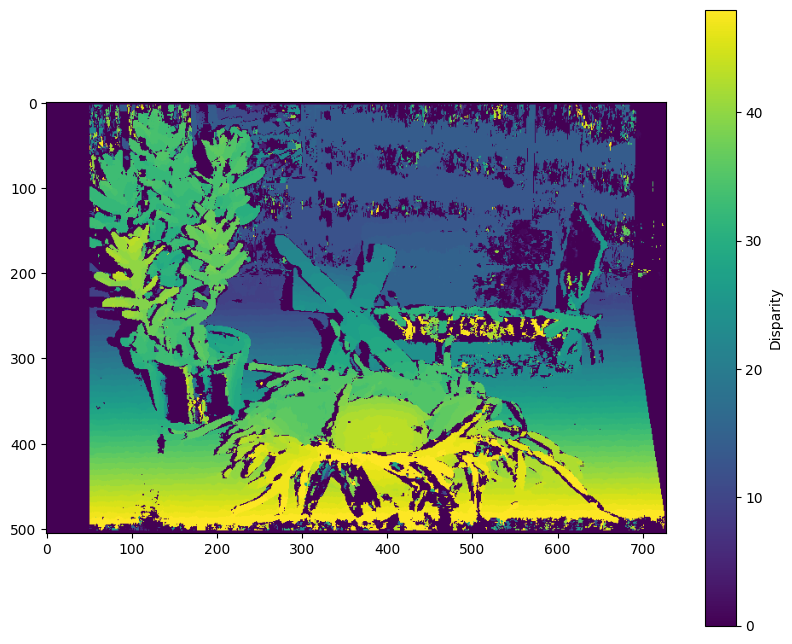

In [ ]:
# Perform cross-checking to resolve ambiguous matches
# IMPORTANT: Store result in `disparity_map`
h, w = disparity_L.shape
disparity_map = np.zeros_like(disparity_L, dtype=np.float32)

threshold = 1

for y in range(h):
    for x in range(w):

        d_left = int(disparity_L[y, x])

        x_right = x - d_left

        if 0 <= x_right < w:
            d_right = int(disparity_R[y, x_right])

            if abs(d_left - d_right) <= threshold:
                disparity_map[y, x] = d_left
            else:
                disparity_map[y, x] = 0
        else:
            disparity_map[y, x] = 0

# --- Visualization ---
if disparity_map is not None:
    plt.figure(figsize=(10, 8))
    plt.imshow(disparity_map, cmap='viridis')
    plt.colorbar(label='Disparity')
    plt.show()


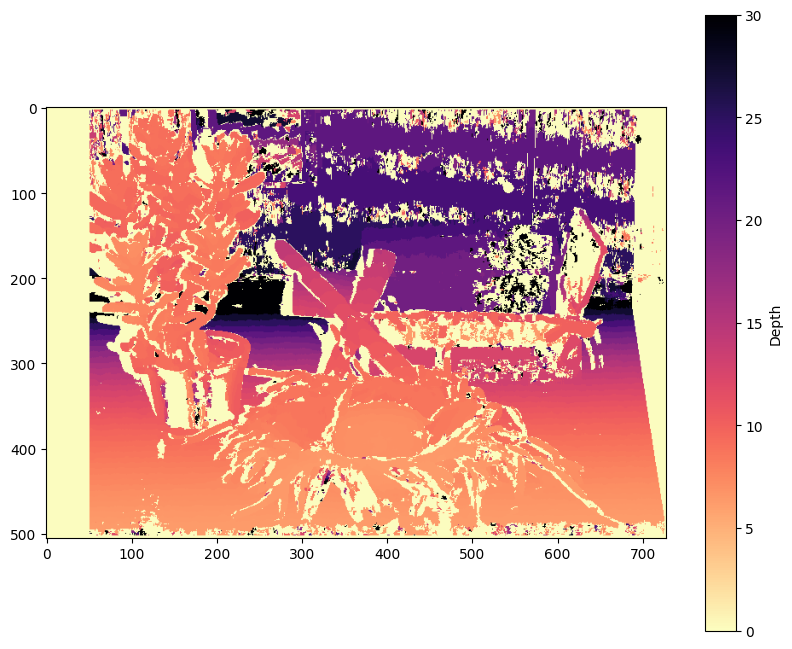

In [ ]:
focal_length_pixels = 1718.2185
baseline_meters = 0.174724
# TODO: Estimate depth from disparity
# IMPORTANT: Store result in `depth_map`
depth_map = np.zeros_like(disparity_map, dtype=np.float32)
valid_pixels = disparity_map > 0

depth_map[valid_pixels] = (
    focal_length_pixels * baseline_meters
) / disparity_map[valid_pixels]

depth_map[~valid_pixels] = np.nan
# --- Visualization ---
if depth_map is not None:
    plt.figure(figsize=(10, 8))
    plt.imshow(np.nan_to_num(depth_map, nan=0, posinf=30), cmap='magma_r', vmax=30)
    plt.colorbar(label='Depth')
    plt.show()


## Exercise 3

**Learning goals:** Smooth depth maps using an MRF

To improve the quality of the depth estimation, you will now apply a Markov Random Field (MRF) to smooth the disparity maps.

1. Install `gco-wrapper`. If you are on Windows, ensure you have a C++ compiler installed.
2. Convert the task of smoothing the disparity map into a MRF problem.
   *Hint: For the MRF, consider defining your unary potentials as the absolute difference between the proposed label and the initial computed disparity. For pairwise potentials, a simple Potts model (penalizing adjacent pixels that have different disparity labels) works well.*
3. Recompute the depth map using your corrected disparity maps and compare them to the previous result.


In [ ]:
# Smooth the depth map using an MRF
labels = np.arange(0, max_disparity + 1)

unary_weight = 1.0
pairwise_weight = 0.8
# IMPORTANT: Store result in `smoothed_depth_map`
smoothed_disparity_map = disparity_map.copy()
h, w = disparity_map.shape

for iteration in range(3):
    new_disparity_map = smoothed_disparity_map.copy()

    for y in range(1, h - 1):
        for x in range(1, w - 1):

            if disparity_map[y, x] == 0:
                continue

            best_label = smoothed_disparity_map[y, x]
            best_cost = np.inf

            neighbors = [
                smoothed_disparity_map[y - 1, x],
                smoothed_disparity_map[y + 1, x],
                smoothed_disparity_map[y, x - 1],
                smoothed_disparity_map[y, x + 1]
            ]

            for label in labels:
                unary_cost = unary_weight * abs(label - disparity_map[y, x])

                pairwise_cost = 0
                for neighbor in neighbors:
                    if label != neighbor:
                        pairwise_cost += pairwise_weight

                total_cost = unary_cost + pairwise_cost

                if total_cost < best_cost:
                    best_cost = total_cost
                    best_label = label

            new_disparity_map[y, x] = best_label

    smoothed_disparity_map = new_disparity_map


smoothed_depth_map = np.zeros_like(smoothed_disparity_map, dtype=np.float32)

valid_pixels = smoothed_disparity_map > 0

smoothed_depth_map[valid_pixels] = (
    focal_length_pixels * baseline_meters
) / smoothed_disparity_map[valid_pixels]

smoothed_depth_map[~valid_pixels] = np.nan

# --- Visualization ---
if smoothed_depth_map is not None:
    plt.figure(figsize=(10, 8))
    #plt.imshow(smoothed_depth_map, cmap='magma_r')
    plt.imshow(np.nan_to_num(smoothed_depth_map, nan=0, posinf=30), cmap='magma_r', vmax=30)
    plt.colorbar(label='Smoothed Depth')
    plt.show()


## Exercise 4 (Optional)

**Learning goals:** Scene surface construction (Marching Squares)

In this final exercise, you will apply surface extraction to create scene surfaces from the estimated depth map.

1. Implement the marching squares algorithm to extract isosurfaces from the depth maps.
   *Hint: Remember to handle the ambiguous saddle cases (where opposite corners share the same sign) by subsampling the center of the cell (averaging the 4 corners) as discussed in the lecture.*
2. Apply your algorithm to your previously created depth maps.
3. Plot the computed surfaces on top of the original images.

# Note: this exercise is ahead of the lecture and therefore optional.  


In [ ]:
isovalues = [5, 15, 25] # you may adjust these values to experiment
colors = ['red', 'green', 'blue']

# Individual plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, iso in enumerate(isovalues):
    segments = extract_surface_marching_squares(smoothed_depth_map, isovalue=iso)
    axes[i].imshow(img1, cmap='gray')
    axes[i].set_title(f'Isovalue {iso}')
    for pt1, pt2 in segments:
        axes[i].plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color=colors[i])
plt.show()

# Combined plot
plt.figure(figsize=(10, 8))
plt.imshow(img1, cmap='gray')
plt.title('Combined Surface Extractions')
for i, iso in enumerate(isovalues):
    segments = extract_surface_marching_squares(smoothed_depth_map, isovalue=iso)
    for pt1, pt2 in segments:
        plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color=colors[i], label=f'Isovalue {iso}' if pt1 == segments[0][0] else '')
plt.legend()
plt.show()
